In [1]:

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config.model_config import get_config
from src.incident_simulation import simulate_incidents

cfg = get_config()

incidents = simulate_incidents(
    n_incidents=100_000,
    seed=20261105,
    config=cfg,
    include_details=True,
)

print("Simulated incidents:", len(incidents))
print("Columns:", len(incidents.columns))


Simulated incidents: 100000
Columns: 77


In [ ]:
#Correlation with technical severity


severity_variables = {
    "affected_customers": "Affected customers",
    "primary_technical_response_hours": "Technical response hours",
    "primary_management_response_hours": "Management response hours",
    "primary_executive_response_hours": "Executive response hours",
    "primary_external_dfir_cost_usd": "External DFIR cost",
    "response_legal_initial_triage_outside_hours": "Initial legal outside hours",
    "response_legal_initial_triage_internal_hours": "Initial legal internal hours",
}

rows = []

for column, label in severity_variables.items():

    if column not in incidents.columns:
        print("Column unavailable:", column)
        continue

    rho = incidents[
        ["technical_severity", column]
    ].corr(method="spearman").iloc[0, 1]

    rows.append({
        "Variable": label,
        "Column": column,
        "Spearman correlation": rho,
    })

correlation_df = pd.DataFrame(rows)

display(
    correlation_df.style.format({
        "Spearman correlation": "{:+.3f}",
    })
)

#We expect positive relationships for these variables, but their magnitudes will differ because of marginal distributions, rounding, and conditional loss mechanisms.


,Variable,Column,Spearman correlation
0,Affected customers,affected_customers,+0.581
1,Technical response hours,primary_technical_response_hours,+0.581
2,Management response hours,primary_management_response_hours,+0.484
3,Executive response hours,primary_executive_response_hours,+0.388
4,External DFIR cost,primary_external_dfir_cost_usd,+0.582
5,Initial legal outside hours,response_legal_initial_triage_outside_hours,+0.437
6,Initial legal internal hours,response_legal_initial_triage_internal_hours,+0.432


,indicator_public_visibility,indicator_notification,indicator_regulatory_engagement,indicator_external_pr_agency,indicator_regulatory_fine,indicator_judgment_or_settlement
severity_quintile,,,,,,
Q1 Lowest,13.51%,55.66%,3.45%,16.45%,0.72%,1.12%
Q2,21.62%,69.97%,6.05%,22.64%,1.94%,2.44%
Q3,28.60%,76.42%,8.53%,28.67%,3.36%,3.81%
Q4,36.06%,82.35%,11.66%,34.57%,5.45%,6.01%
Q5 Highest,50.98%,89.46%,20.03%,46.45%,12.98%,11.72%


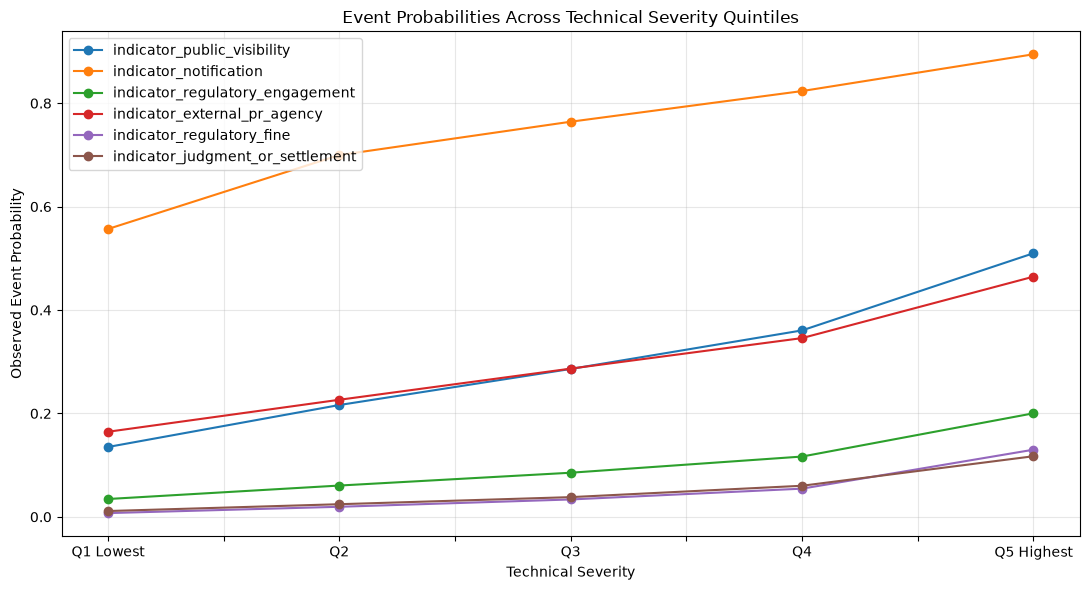

In [3]:
#Severity and event probabilities


severity_groups = incidents.copy()

severity_groups["severity_quintile"] = pd.qcut(
    severity_groups["technical_severity"],
    q=5,
    labels=[
        "Q1 Lowest",
        "Q2",
        "Q3",
        "Q4",
        "Q5 Highest",
    ],
)

indicator_columns = [
    "indicator_public_visibility",
    "indicator_notification",
    "indicator_regulatory_engagement",
    "indicator_external_pr_agency",
    "indicator_regulatory_fine",
    "indicator_judgment_or_settlement",
]

severity_event_rates = (
    severity_groups
    .groupby(
        "severity_quintile",
        observed=True,
    )[indicator_columns]
    .mean()
)

display(
    severity_event_rates.style.format("{:.2%}")
)

ax = severity_event_rates.plot(
    figsize=(11, 6),
    marker="o",
)

ax.set_title(
    "Event Probabilities Across Technical Severity Quintiles"
)
ax.set_xlabel("Technical Severity")
ax.set_ylabel("Observed Event Probability")
ax.grid(alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,mean_loss_usd,median_loss_usd,p95_loss_usd,mean_affected_customers
severity_quintile,,,,
Q1 Lowest,"$496,986","$420,127","$1,072,816","1,130"
Q2,"$775,679","$674,591","$1,595,720","1,384"
Q3,"$1,035,186","$909,470","$2,105,080","1,549"
Q4,"$1,413,036","$1,219,847","$2,853,418","1,716"
Q5 Highest,"$2,428,369","$2,092,913","$5,182,351","1,980"


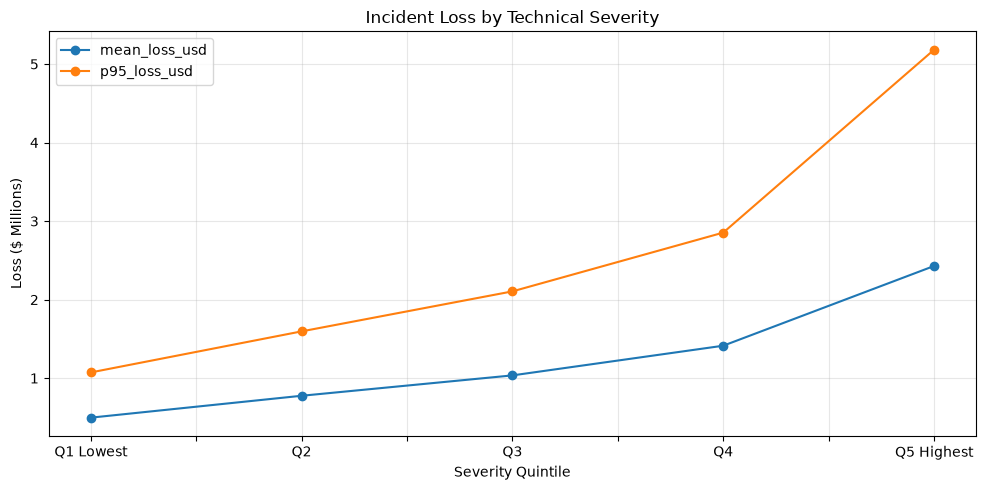

In [ ]:
#How does severity affect total loss?


loss_by_severity = (
    severity_groups
    .groupby(
        "severity_quintile",
        observed=True,
    )
    .agg(
        mean_loss_usd=(
            "total_incident_loss_usd", "mean"
        ),
        median_loss_usd=(
            "total_incident_loss_usd", "median"
        ),
        p95_loss_usd=(
            "total_incident_loss_usd",
            lambda x: x.quantile(0.95),
        ),
        mean_affected_customers=(
            "affected_customers", "mean"
        ),
    )
)

display(
    loss_by_severity.style.format({
        "mean_loss_usd": "${:,.0f}",
        "median_loss_usd": "${:,.0f}",
        "p95_loss_usd": "${:,.0f}",
        "mean_affected_customers": "{:,.0f}",
    })
)

ax = (
    loss_by_severity[
        ["mean_loss_usd", "p95_loss_usd"]
    ] / 1_000_000
).plot(
    figsize=(10, 5),
    marker="o",
)

ax.set_title(
    "Incident Loss by Technical Severity"
)
ax.set_ylabel("Loss ($ Millions)")
ax.set_xlabel("Severity Quintile")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#We would generally expect more severe incidents to have higher average losses. The precise pattern is not guaranteed to be perfectly increasing in finite samples.


,primary_loss_usd,secondary_response_planning_loss_usd,secondary_fines_judgement_loss_usd,secondary_reputation_loss_usd
primary_loss_usd,+1.000,+0.422,+0.172,+0.451
secondary_response_planning_loss_usd,+0.422,+1.000,+0.292,+0.398
secondary_fines_judgement_loss_usd,+0.172,+0.292,+1.000,+0.202
secondary_reputation_loss_usd,+0.451,+0.398,+0.202,+1.000


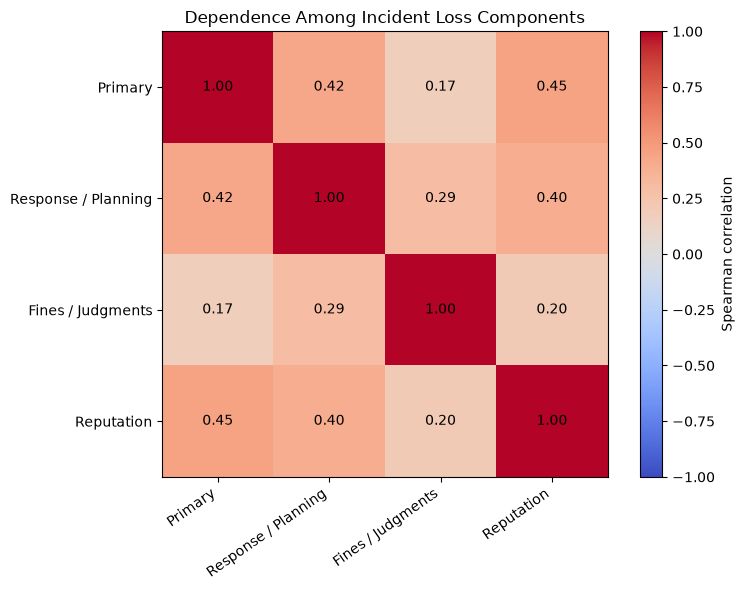

In [7]:

#Correlations among loss components

loss_columns = [
    "primary_loss_usd",
    "secondary_response_planning_loss_usd",
    "secondary_fines_judgement_loss_usd",
    "secondary_reputation_loss_usd",
]

loss_corr = incidents[
    loss_columns
].corr(method="spearman")

display(loss_corr.style.format("{:+.3f}"))

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    loss_corr.to_numpy(),
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
)

ax.set_xticks(range(len(loss_columns)))
ax.set_yticks(range(len(loss_columns)))

short_labels = [
    "Primary",
    "Response / Planning",
    "Fines / Judgments",
    "Reputation",
]

ax.set_xticklabels(short_labels, rotation=35, ha="right")
ax.set_yticklabels(short_labels)

for i in range(len(loss_columns)):
    for j in range(len(loss_columns)):
        ax.text(
            j, i,
            f"{loss_corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
        )

fig.colorbar(im, ax=ax, label="Spearman correlation")

ax.set_title("Dependence Among Incident Loss Components")

plt.tight_layout()
plt.show()


In [8]:
#Compare high-loss and ordinary incidents


threshold = incidents[
    "total_incident_loss_usd"
].quantile(0.99)

incidents["top_1pct_loss"] = (
    incidents["total_incident_loss_usd"] >= threshold
)

comparison_columns = [
    "technical_severity",
    "affected_customers",
    "indicator_public_visibility",
    "indicator_notification",
    "indicator_regulatory_engagement",
    "indicator_regulatory_fine",
    "indicator_judgment_or_settlement",
]

tail_comparison = (
    incidents
    .groupby("top_1pct_loss")[
        comparison_columns
    ]
    .mean()
    .T
)

tail_comparison.columns = [
    "Other incidents",
    "Top 1% loss incidents",
]

tail_comparison["Difference"] = (
    tail_comparison["Top 1% loss incidents"]
    - tail_comparison["Other incidents"]
)

print(
    "99th percentile incident loss:",
    f"${threshold:,.0f}"
)

display(tail_comparison.round(4))


99th percentile incident loss: $5,415,932


,Other incidents,Top 1% loss incidents,Difference
technical_severity,-0.0215,1.8316,1.8531
affected_customers,1545.2969,2173.2700,627.9731
indicator_public_visibility,0.2964,0.8090,0.5126
indicator_notification,0.7460,0.9200,0.1740
indicator_regulatory_engagement,0.0932,0.7140,0.6208
indicator_regulatory_fine,0.0426,0.6700,0.6274
indicator_judgment_or_settlement,0.0469,0.3800,0.3331


In [9]:

# Cell 7 — Inspect dependence configuration for stress testing

from pprint import pprint

print("TOP-LEVEL CONFIGURATION KEYS")
pprint(list(cfg.keys()))

print("\nSECTIONS CONTAINING DEPENDENCE SETTINGS")

for key, value in cfg.items():
    key_lower = key.lower()

    if any(term in key_lower for term in [
        "correl", "copula", "calibrat",
        "probabil", "severity", "indicator"
    ]):
        print(f"\n{key}:")
        pprint(value, depth=4)


TOP-LEVEL CONFIGURATION KEYS
['metadata',
 'organization',
 'simulation',
 'frequency',
 'dependence',
 'primary_response',
 'secondary_response',
 'fines_and_judgments',
 'reputation',
 'probabilities',
 'calibration',
 'sensitivity',
 'open_decisions']

SECTIONS CONTAINING DEPENDENCE SETTINGS

probabilities:
{'affected_churn': {'family': 'calibrated_logistic',
                    'intercept': None,
                    'regulator_or': 1.0,
                    'severity_or': 1.5,
                    'target': 0.002,
                    'target_type': 'customer_weighted',
                    'visibility_or': 2.0},
 'external_pr_agency': {'family': 'calibrated_logistic',
                        'intercept': None,
                        'regulator_or': 1.0,
                        'severity_or': 1.5,
                        'target': 0.3,
                        'target_type': 'unconditional',
                        'visibility_or': 3.0},
 'judgment_or_settlement': {'family': 'calibrate

In [10]:

from pprint import pprint

print("DEPENDENCE CONFIGURATION")
pprint(cfg["dependence"], depth=6)


DEPENDENCE CONFIGURATION
{'copula': 'one_factor_gaussian',
 'correlations_latent_normal': {'affected_customers': 0.6,
                                'executive_response_hours': 0.4,
                                'external_dfir_cost_usd': 0.6,
                                'it_security_management_hours': 0.5,
                                'legal_initial_internal_hours': 0.5,
                                'legal_initial_outside_hours': 0.5,
                                'legal_notification_internal_hours': 0.5,
                                'legal_notification_outside_hours': 0.5,
                                'legal_regulator_internal_hours': 0.5,
                                'legal_regulator_outside_hours': 0.5,
                                'legal_remediation_internal_hours': 0.5,
                                'legal_remediation_outside_hours': 0.5,
                                'notification_coordination_hours': 0.4,
                                'pr_interna

In [11]:

#Run the three dependence scenarios
import importlib

import src.model_validation_dependence as dependence

importlib.reload(dependence)

results_df, annual_by_scenario = (
    dependence.run_dependence_stress_test(
        n_years=100_000,
        seed=20261106,
        base_config=cfg,
    )
)

risk_columns = [
    "scenario",
    "dependence_multiplier",
    "aal_usd",
    "var_95_usd",
    "var_99_usd",
    "tvar_95_usd",
    "tvar_99_usd",
    "aal_change_vs_baseline_pct",
]

display(
    results_df[risk_columns].style.format({
        "dependence_multiplier": "{:.2f}",
        "aal_usd": "${:,.0f}",
        "var_95_usd": "${:,.0f}",
        "var_99_usd": "${:,.0f}",
        "tvar_95_usd": "${:,.0f}",
        "tvar_99_usd": "${:,.0f}",
        "aal_change_vs_baseline_pct": "{:+.2f}%",
    })
)


,scenario,dependence_multiplier,aal_usd,var_95_usd,var_99_usd,tvar_95_usd,tvar_99_usd,aal_change_vs_baseline_pct
0,Weaker,0.50,"$274,539","$1,712,513","$3,109,267","$2,596,618","$4,178,417",-0.75%
1,Baseline,1.00,"$276,605","$1,776,747","$3,783,466","$3,035,550","$5,158,543",+0.00%
2,Stronger,1.25,"$276,596","$1,750,658","$4,227,932","$3,279,233","$5,953,188",-0.00%


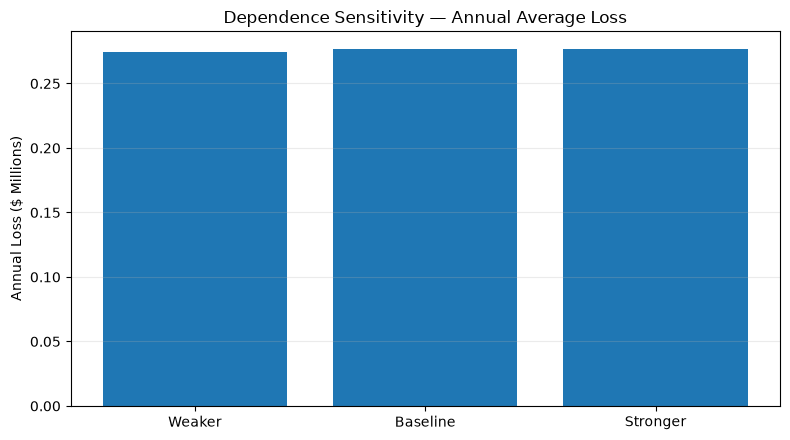

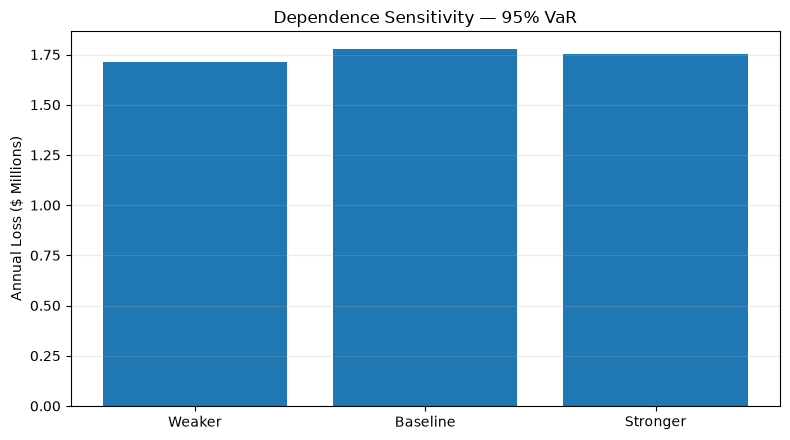

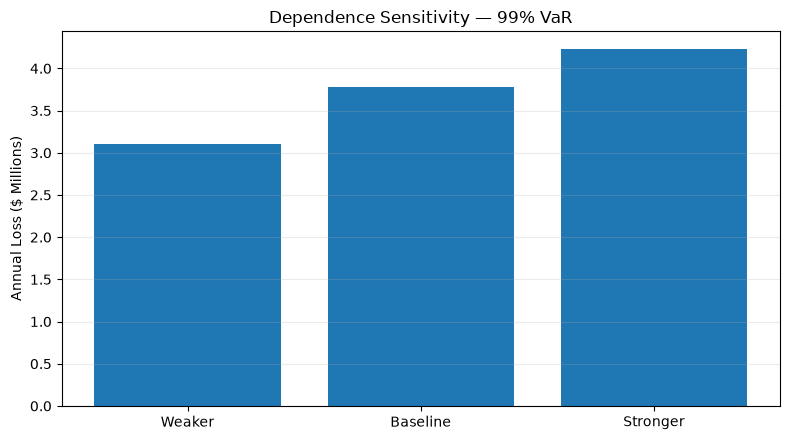

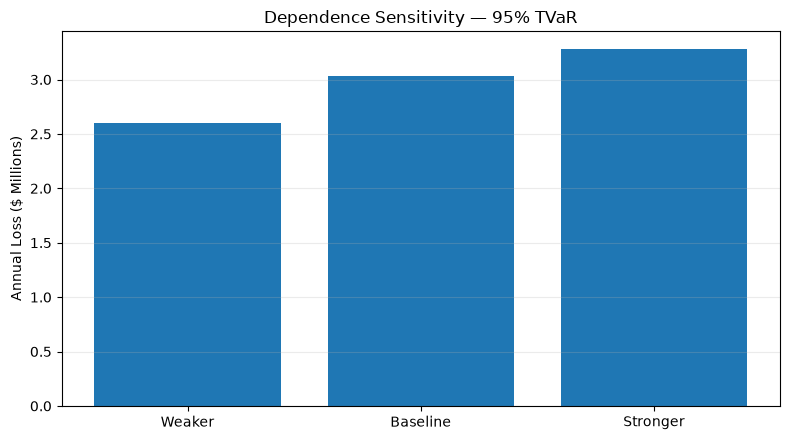

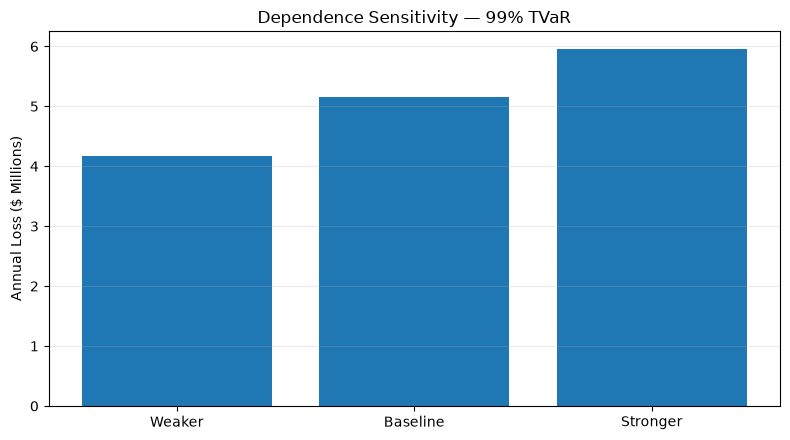

In [12]:

#Compare AAL and tail-risk metrics

metrics = {
    "aal_usd": "Annual Average Loss",
    "var_95_usd": "95% VaR",
    "var_99_usd": "99% VaR",
    "tvar_95_usd": "95% TVaR",
    "tvar_99_usd": "99% TVaR",
}

for metric, title in metrics.items():

    fig, ax = plt.subplots(figsize=(8, 4.5))

    ax.bar(
        results_df["scenario"],
        results_df[metric] / 1_000_000,
    )

    ax.set_ylabel("Annual Loss ($ Millions)")
    ax.set_title(
        f"Dependence Sensitivity — {title}"
    )

    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()


Scenario,Baseline,Stronger,Weaker
Threshold,,,
2000000,4.125%,4.143%,3.489%
5000000,0.398%,0.617%,0.158%
10000000,0.010%,0.039%,0.011%
15000000,0.002%,0.004%,0.003%


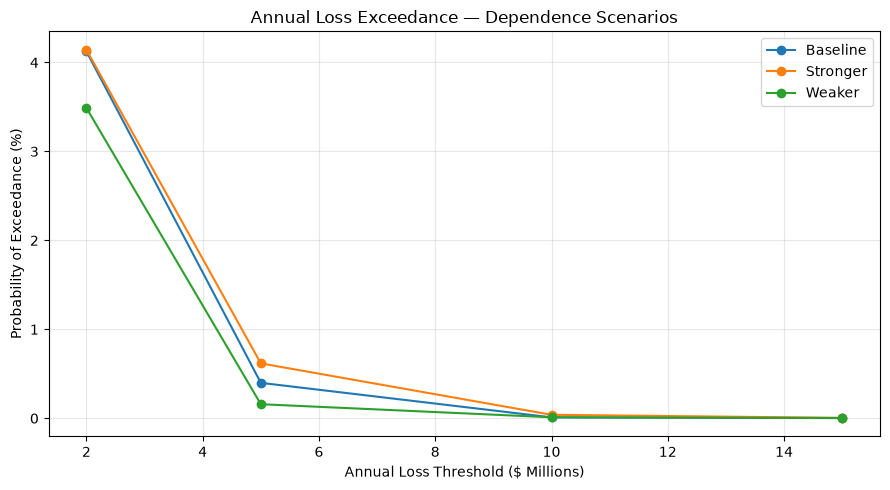

In [13]:
#Exceedance probabilities


thresholds = [
    2_000_000,
    5_000_000,
    10_000_000,
    15_000_000,
]

rows = []

for scenario_name, annual in annual_by_scenario.items():

    losses = annual[
        "total_annual_loss_usd"
    ].to_numpy()

    for threshold in thresholds:

        rows.append({
            "Scenario": scenario_name,
            "Threshold": threshold,
            "Probability": np.mean(
                losses > threshold
            ),
        })

exceedance_df = pd.DataFrame(rows)

display(
    exceedance_df.pivot(
        index="Threshold",
        columns="Scenario",
        values="Probability",
    ).style.format("{:.3%}")
)

fig, ax = plt.subplots(figsize=(9, 5))

for scenario_name, group in exceedance_df.groupby(
    "Scenario"
):

    ax.plot(
        group["Threshold"] / 1_000_000,
        group["Probability"] * 100,
        marker="o",
        label=scenario_name,
    )

ax.set_xlabel("Annual Loss Threshold ($ Millions)")
ax.set_ylabel("Probability of Exceedance (%)")
ax.set_title(
    "Annual Loss Exceedance — Dependence Scenarios"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [14]:
#Check whether incident frequency stays unchanged


frequency_rows = []

for scenario_name, annual in annual_by_scenario.items():

    frequency_rows.append({
        "Scenario": scenario_name,
        "Campaigns per year":
            annual["campaign_count"].mean(),
        "Incidents per year":
            annual["successful_incident_count"].mean(),
        "P(at least one incident)":
            (
                annual["successful_incident_count"] > 0
            ).mean(),
    })

frequency_df = pd.DataFrame(frequency_rows)

display(
    frequency_df.style.format({
        "Campaigns per year": "{:.4f}",
        "Incidents per year": "{:.4f}",
        "P(at least one incident)": "{:.3%}",
    })
)

assert np.allclose(
    frequency_df["Campaigns per year"],
    frequency_df["Campaigns per year"].iloc[0],
)

assert np.allclose(
    frequency_df["Incidents per year"],
    frequency_df["Incidents per year"].iloc[0],
)

print("PASS: Annual incident frequency is unchanged.")


,Scenario,Campaigns per year,Incidents per year,P(at least one incident)
0,Weaker,3.0109,0.2241,20.077%
1,Baseline,3.0109,0.2241,20.077%
2,Stronger,3.0109,0.2241,20.077%


PASS: Annual incident frequency is unchanged.
